# Charlottesville Crash and Weather Data Exploration

This notebook explores reported crashes **inside the City of Charlottesville**, using the dataset compiled October 9, 2026. The main analysis covers **2017–2025**, so partial 2026 records do not distort comparisons. It contains data checks and 12 plots, followed by guidance for the forecasting project.

Run cells from top to bottom. Place this notebook in the dataset folder, or extract the accompanying ZIP and open the notebook there. Requires Python 3.9+, `pandas`, `numpy`, and `matplotlib`. If needed, install those packages in your own notebook environment with `%pip install pandas numpy matplotlib`.

These are descriptive analyses. Weather comparisons show associations, not causes. Reported counts are not crash risk per trip or mile.

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
BLUE, ORANGE = "#235789", "#d97732"
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# Set DATA_DIR manually if your files are stored elsewhere.
candidates = [Path.cwd(), Path.cwd()/"cville_crash_dataset", Path.cwd().parent/"cville_crash_dataset"]
DATA_DIR = next((p for p in candidates if (p/"cville_daily_crashes_weather.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Put the notebook beside the CSVs, or set DATA_DIR to their folder.")

incidents = pd.read_csv(DATA_DIR/"cville_crash_incidents.csv", dtype={"crash_id": "string", "physical_jurisdiction_code": "string"})
daily = pd.read_csv(DATA_DIR/"cville_daily_crashes_weather.csv")
weather = pd.read_csv(DATA_DIR/"cville_weather_daily.csv")
for frame in [incidents, daily, weather]:
    frame["date_local"] = pd.to_datetime(frame["date_local"], errors="raise")
study = incidents.loc[incidents.date_local.between(daily.date_local.min(), daily.date_local.max())].copy()
daily = daily.sort_values("date_local").reset_index(drop=True)
daily["weekday"] = pd.Categorical(daily.date_local.dt.day_name(), categories=WEEKDAYS, ordered=True)
print("Data folder:", DATA_DIR)
print(f"All incidents: {len(incidents):,}; study incidents: {len(study):,}; study days: {len(daily):,}")
display(daily.head(3))

Data folder: /workspace/scratch/a816240b5ba8/cville_crash_dataset
All incidents: 5,432; study incidents: 5,197; study days: 3,287


,date_local,year,month,day_of_month,weekday_mon0,is_weekend,day_of_year,month_sin,month_cos,crash_count,injury_crash_count,fatal_crash_count,persons_injured,persons_killed,crash_count_lag1,crash_count_lag7,crash_count_lag14,crash_count_prior7_mean,crash_count_prior28_mean,observed_temp_max_c,observed_temp_min_c,observed_temp_mean_c,observed_precip_mm,observed_snowfall_cm,observed_wind_max_kmh,temp_max_c_lag7,temp_min_c_lag7,temp_mean_c_lag7,precip_mm_lag7,snowfall_cm_lag7,wind_max_kmh_lag7,coverage_status,source_ref,weekday
0,2017-01-01,2017,1,1,6,1,1,0.0,1.0,2,1,0,1,0,NaN,NaN,NaN,NaN,NaN,13.6,2.9,7.9,0.0,0.0,15.3,9.4,5.0,7.5,0.8,0.0,6.3,complete_calendar_year_range; source_completen...,"[1],[2],[3]",Sunday
1,2017-01-02,2017,1,2,0,0,2,0.0,1.0,0,0,0,0,0,2.0,NaN,NaN,NaN,NaN,8.4,5.6,6.6,8.4,0.0,9.7,9.5,5.8,7.4,0.5,0.0,15.3,complete_calendar_year_range; source_completen...,"[1],[2],[3]",Monday
2,2017-01-03,2017,1,3,1,0,3,0.0,1.0,0,0,0,0,0,0.0,NaN,NaN,NaN,NaN,9.0,5.4,6.8,28.2,0.0,10.2,19.3,9.8,13.9,0.0,0.0,20.8,complete_calendar_year_range; source_completen...,"[1],[2],[3]",Tuesday


## 1. Verify the data before plotting

Check keys, city filtering, dates, aggregation, joins, and forecast lags. A zero daily count means no record in this source for that date. It is not proof of complete reporting.

In [ ]:
assert incidents.crash_id.is_unique, "Duplicate crash identifiers"
assert daily.date_local.is_unique, "Duplicate daily dates"
assert incidents.physical_jurisdiction_code.eq("104").all(), "Records outside the city filter"
expected_dates = pd.date_range(daily.date_local.min(), daily.date_local.max(), freq="D")
assert daily.date_local.tolist() == expected_dates.tolist(), "Calendar gaps"
assert daily.crash_count.sum() == len(study), "Incident and daily totals disagree"
recount = study.groupby("date_local").size().reindex(expected_dates, fill_value=0)
np.testing.assert_array_equal(daily.crash_count.to_numpy(), recount.to_numpy())
for lag in [1, 7, 14]:
    np.testing.assert_allclose(daily[f"crash_count_lag{lag}"], daily.crash_count.shift(lag), equal_nan=True)
for window in [7, 28]:
    expected = daily.crash_count.shift(1).rolling(window).mean()
    np.testing.assert_allclose(daily[f"crash_count_prior{window}_mean"], expected, atol=1e-6, equal_nan=True)
joined = daily.merge(weather[["date_local", "precip_mm"]], on="date_local", how="left", validate="one_to_one")
np.testing.assert_allclose(joined.observed_precip_mm, joined.precip_mm, equal_nan=True)
print("Passed: unique IDs, city filter, continuous dates, daily counts, count lags, and weather join.")

summary = pd.Series({"start": daily.date_local.min().date(), "end": daily.date_local.max().date(),
    "study_crashes": len(study), "days": len(daily), "mean_daily_crashes": daily.crash_count.mean(),
    "variance_daily_crashes": daily.crash_count.var(), "zero_record_days": daily.crash_count.eq(0).sum(),
    "zero_record_days_pct": daily.crash_count.eq(0).mean()*100, "maximum_daily_crashes": daily.crash_count.max()})
display(summary.to_frame("value"))
display(daily.crash_count.describe().to_frame("daily crash count"))

Passed: unique IDs, city filter, continuous dates, daily counts, count lags, and weather join.


,value
start,2017-01-01
end,2025-12-31
study_crashes,5197
days,3287
mean_daily_crashes,1.581077
variance_daily_crashes,1.888053
zero_record_days,771
zero_record_days_pct,23.456039
maximum_daily_crashes,8


,daily crash count
count,3287.000000
mean,1.581077
std,1.374065
min,0.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,8.000000


## 2. Missing values

The first 1, 7, 14, or 28 days lack the relevant preceding count history. Keep those values missing; they should not be replaced by zero. Review other missing values separately.

,missing rows
crash_count_prior28_mean,28
crash_count_lag14,14
crash_count_prior7_mean,7
crash_count_lag7,7
crash_count_lag1,1


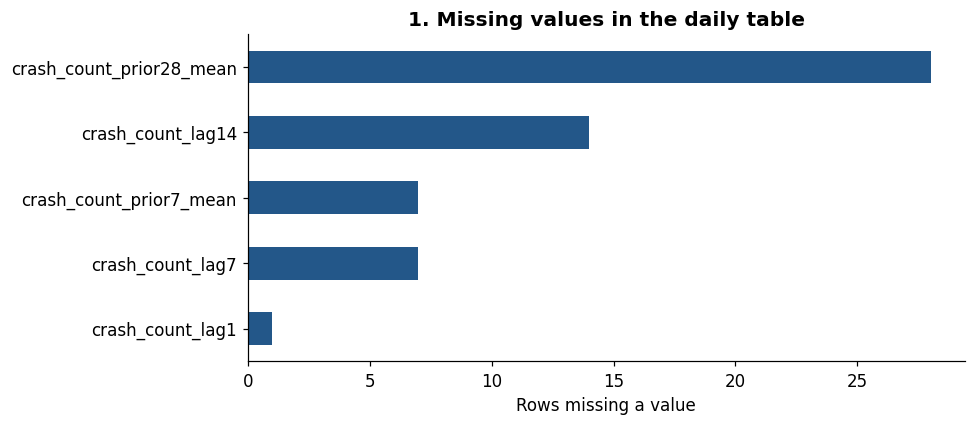

In [ ]:
missing = daily.isna().sum().sort_values(ascending=False)
display(missing[missing.gt(0)].to_frame("missing rows"))
fig, ax = plt.subplots(figsize=(9, 4))
nonzero = missing[missing.gt(0)].sort_values()
if len(nonzero):
    nonzero.plot.barh(ax=ax, color=BLUE)
else:
    ax.text(.5, .5, "No missing daily values", ha="center", transform=ax.transAxes)
ax.set(title="1. Missing values in the daily table", xlabel="Rows missing a value", ylabel="")
plt.tight_layout(); plt.show()

## 3. Changes over time

Monthly and annual totals show longer trends. Full calendar years are comparable in length, but reporting completeness has not been independently verified. Changes around 2020 may reflect many factors; this notebook does not establish a cause.

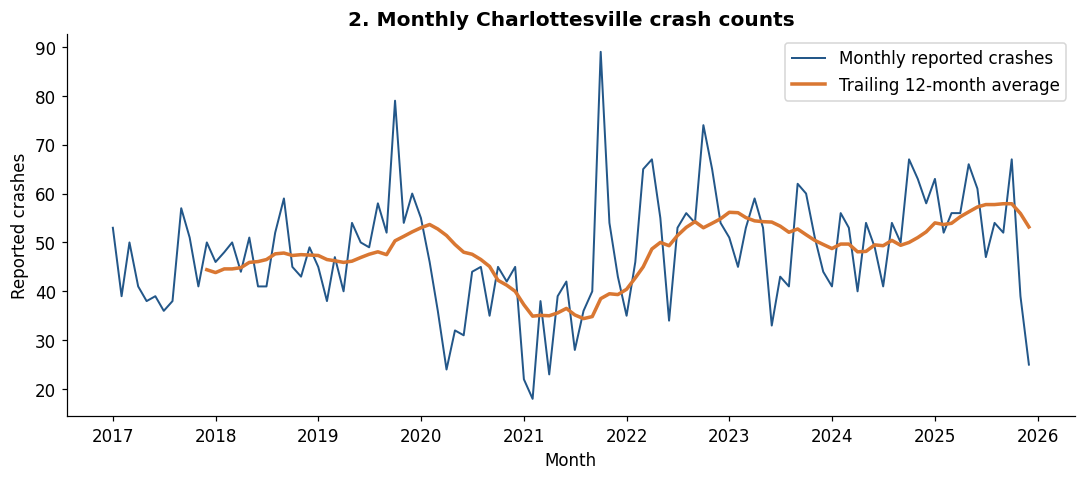

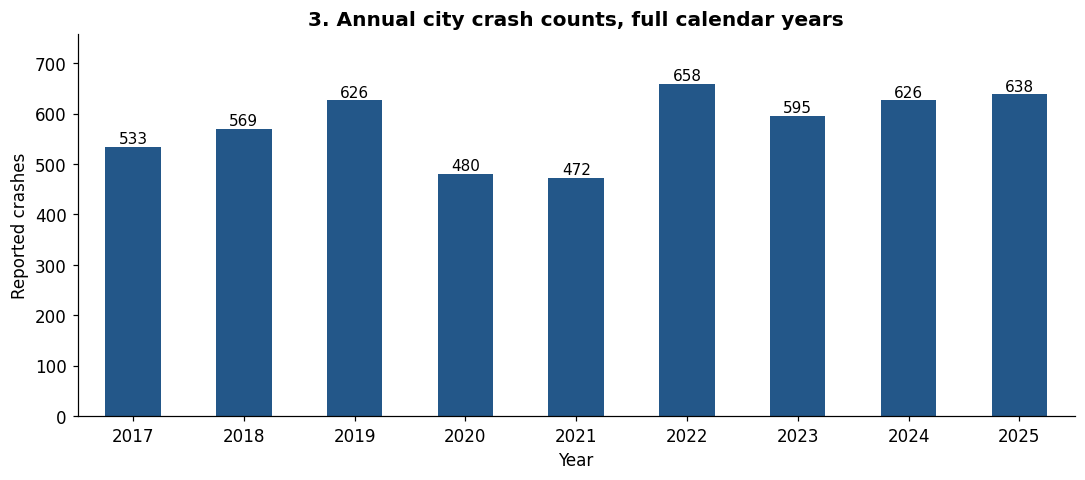

,reported crashes
year,
2017,533
2018,569
2019,626
2020,480
2021,472
2022,658
2023,595
2024,626
2025,638


In [ ]:
monthly = daily.set_index("date_local").crash_count.resample("MS").sum()
fig, ax = plt.subplots()
ax.plot(monthly.index, monthly, color=BLUE, linewidth=1.3, label="Monthly reported crashes")
ax.plot(monthly.index, monthly.rolling(12, min_periods=12).mean(), color=ORANGE, linewidth=2.3, label="Trailing 12-month average")
ax.set(title="2. Monthly Charlottesville crash counts", xlabel="Month", ylabel="Reported crashes")
ax.legend(); plt.tight_layout(); plt.show()

annual = daily.groupby("year").crash_count.sum()
fig, ax = plt.subplots()
annual.plot.bar(ax=ax, color=BLUE, rot=0)
for i, count in enumerate(annual): ax.text(i, count+7, str(count), ha="center", fontsize=10)
ax.set(title="3. Annual city crash counts, full calendar years", xlabel="Year", ylabel="Reported crashes")
ax.set_ylim(0, annual.max()*1.15)
plt.tight_layout(); plt.show()
display(annual.to_frame("reported crashes"))

## 4. Daily count distribution and weekday patterns

Daily counts include zero-record days. Compare the mean and variance when considering a Poisson model; a difference is a preliminary diagnostic, not a test of conditional model fit. Weekday averages divide by the number of calendar days of each weekday.

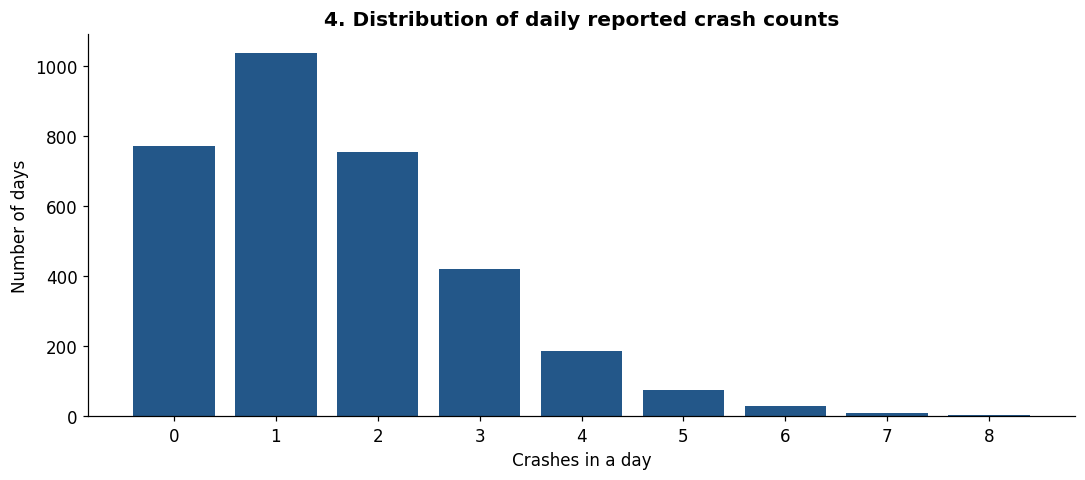

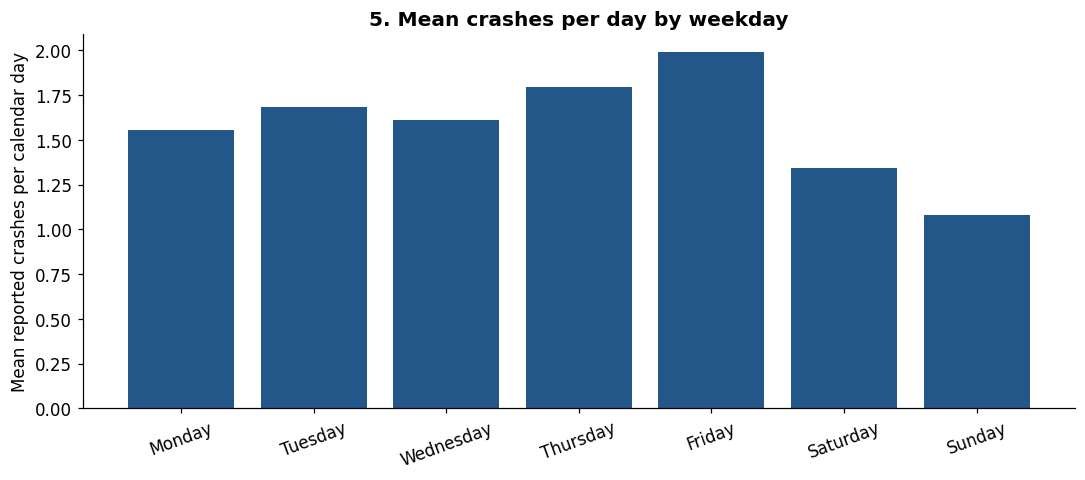

,mean,crashes,calendar_days
weekday,,,
Monday,1.555319,731,470
Tuesday,1.685106,792,470
Wednesday,1.612766,758,470
Thursday,1.797441,843,469
Friday,1.989339,933,469
Saturday,1.345416,631,469
Sunday,1.082979,509,470


In [ ]:
fig, ax = plt.subplots()
freq = daily.crash_count.value_counts().sort_index()
ax.bar(freq.index, freq.values, color=BLUE)
ax.set(title="4. Distribution of daily reported crash counts", xlabel="Crashes in a day", ylabel="Number of days", xticks=freq.index)
plt.tight_layout(); plt.show()

weekday = daily.groupby("weekday", observed=False).crash_count.agg(["mean", "sum", "count"])
fig, ax = plt.subplots()
ax.bar(WEEKDAYS, weekday["mean"], color=BLUE)
ax.set(title="5. Mean crashes per day by weekday", xlabel="", ylabel="Mean reported crashes per calendar day")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
display(weekday.rename(columns={"sum":"crashes", "count":"calendar_days"}))

## 5. Time of day

Crash clock time comes from the separate HHMM field, not the midnight date value. Recorded midnight values may include source defaults. Each heatmap cell is the mean number of crashes in that hour per calendar day of that weekday; without traffic volume, this is not risk per vehicle.

Incidents without a valid hour: 0


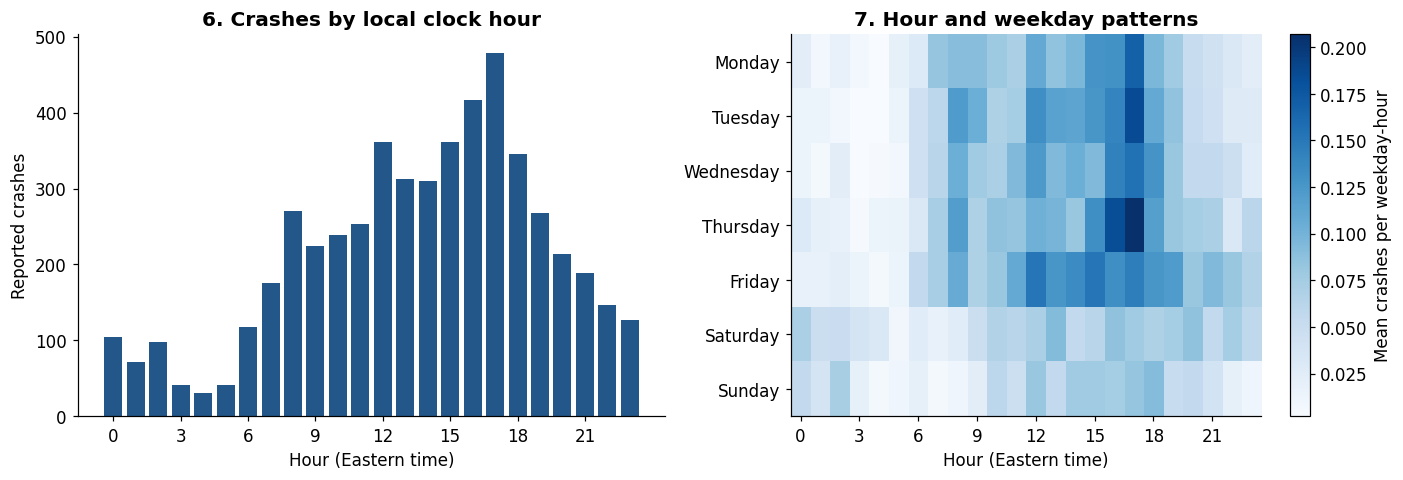

In [ ]:
hour = pd.to_numeric(study.hour_local, errors="coerce")
valid = hour.between(0, 23)
hour_counts = hour[valid].astype(int).value_counts().reindex(range(24), fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(hour_counts.index, hour_counts.values, color=BLUE)
axes[0].set(title="6. Crashes by local clock hour", xlabel="Hour (Eastern time)", ylabel="Reported crashes", xticks=range(0,24,3))
timed = study.loc[valid].copy(); timed["hour"] = hour[valid].astype(int)
table = pd.crosstab(timed.weekday_mon0, timed.hour).reindex(index=range(7), columns=range(24), fill_value=0)
days_by_weekday = daily.groupby("weekday_mon0").size().reindex(range(7))
rates = table.div(days_by_weekday, axis=0)
im = axes[1].imshow(rates, aspect="auto", cmap="Blues", interpolation="nearest")
axes[1].set(title="7. Hour and weekday patterns", xlabel="Hour (Eastern time)", yticks=range(7), yticklabels=WEEKDAYS, xticks=range(0,24,3))
fig.colorbar(im, ax=axes[1], label="Mean crashes per weekday-hour")
plt.tight_layout(); plt.show()
print("Incidents without a valid hour:", (~valid).sum())

## 6. Severity and collision types

These columns describe crashes after they occur. They are useful for EDA and potential alternative outcomes, but must not be used to predict how many crashes will occur that same day. Labels below come from the original API codebook.

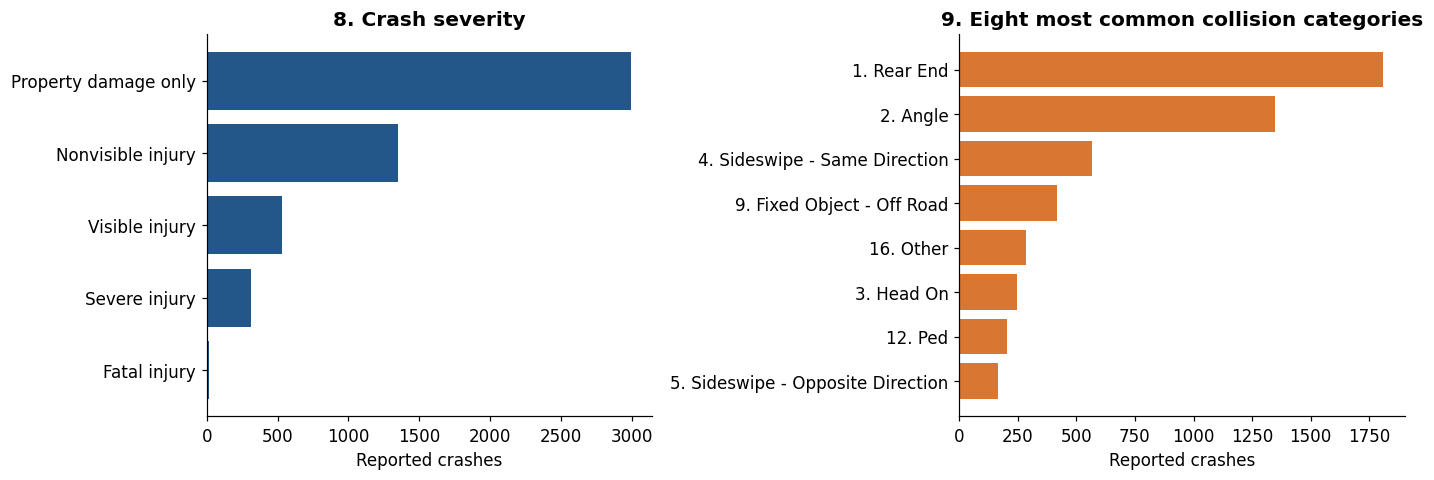

,crashes,percent
severity_code,,
Property damage only,2993,57.590918
Nonvisible injury,1348,25.938041
Visible injury,531,10.217433
Severe injury,310,5.964980
Fatal injury,15,0.288628


In [ ]:
severity_order = ["O", "C", "B", "A", "K"]
labels = {"O":"Property damage only", "C":"Nonvisible injury", "B":"Visible injury", "A":"Severe injury", "K":"Fatal injury"}
severity = study.severity_code.value_counts().reindex(severity_order, fill_value=0)
collision = study.collision_type_label.fillna("Unmapped / missing").value_counts().head(8).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh([labels[k] for k in severity_order], severity.values, color=BLUE); axes[0].invert_yaxis()
axes[0].set(title="8. Crash severity", xlabel="Reported crashes")
axes[1].barh(collision.index, collision.values, color=ORANGE)
axes[1].set(title="9. Eight most common collision categories", xlabel="Reported crashes")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"crashes":severity, "percent":100*severity/severity.sum()}).rename(index=labels))

## 7. Reported crash locations

This uses the source latitude and longitude, without a background street map. Dense bins indicate more recorded crashes, not necessarily greater risk. City membership is determined by the jurisdiction code, not this plot.

Missing coordinates: 0


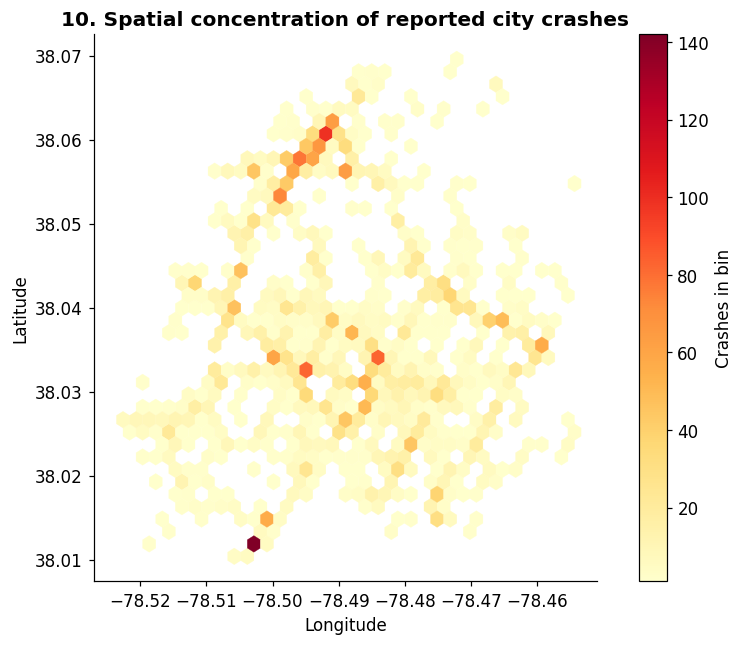

In [ ]:
geo = study.dropna(subset=["latitude", "longitude"])
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.hexbin(geo.longitude, geo.latitude, gridsize=35, mincnt=1, cmap="YlOrRd", linewidths=.2)
ax.set(title="10. Spatial concentration of reported city crashes", xlabel="Longitude", ylabel="Latitude")
ax.set_aspect(1/np.cos(np.deg2rad(38.03)))
fig.colorbar(im, ax=ax, label="Crashes in bin")
plt.tight_layout(); plt.show()
print("Missing coordinates:", len(study)-len(geo))

## 8. Weather associations

For description, compare counts with weather on the same day. These **observed target-day weather values are not advance forecasting features**. Temperature and precipitation groups have different numbers of days, shown below; seasonality and travel exposure could explain associations.

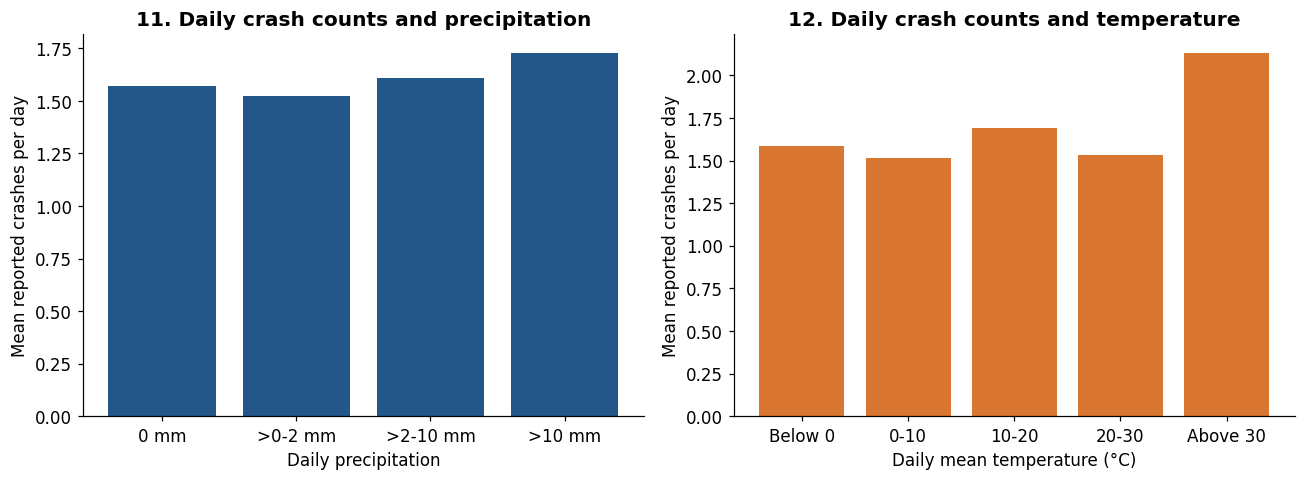

,mean_crashes,days
rain_group,,
0 mm,1.570862,1764
>0-2 mm,1.522111,701
>2-10 mm,1.609943,523
>10 mm,1.729097,299


,mean_crashes,days
temp_group,,
Below 0,1.584615,130
0-10,1.514851,909
10-20,1.691321,1014
20-30,1.531583,1219
Above 30,2.133333,15


In [ ]:
rain = daily.copy()
rain["rain_group"] = pd.cut(rain.observed_precip_mm, bins=[-np.inf, 0, 2, 10, np.inf], labels=["0 mm", ">0-2 mm", ">2-10 mm", ">10 mm"])
rain_summary = rain.groupby("rain_group", observed=False).crash_count.agg(["mean", "count"])
temperature = daily.copy()
temperature["temp_group"] = pd.cut(temperature.observed_temp_mean_c, bins=[-np.inf, 0, 10, 20, 30, np.inf], labels=["Below 0", "0-10", "10-20", "20-30", "Above 30"], right=False)
temp_summary = temperature.groupby("temp_group", observed=False).crash_count.agg(["mean", "count"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(rain_summary.index.astype(str), rain_summary["mean"], color=BLUE)
axes[0].set(title="11. Daily crash counts and precipitation", xlabel="Daily precipitation", ylabel="Mean reported crashes per day")
axes[1].bar(temp_summary.index.astype(str), temp_summary["mean"], color=ORANGE)
axes[1].set(title="12. Daily crash counts and temperature", xlabel="Daily mean temperature (°C)", ylabel="Mean reported crashes per day")
plt.tight_layout(); plt.show()
display(rain_summary.rename(columns={"count":"days", "mean":"mean_crashes"}))
display(temp_summary.rename(columns={"count":"days", "mean":"mean_crashes"}))

## 9. Implications for modeling

- Use `crash_count` as the daily outcome. Calendar variables and prior counts provide baseline predictors.
- Candidate advance weather features are columns ending in `_lag7`, not `observed_*`. Seven days is longer than ERA5's approximately five-day release delay, but historical weather may still be revised.
- Report publication timestamps are unavailable, so even lagged crash counts are retrospective rather than proven available at a real forecast origin.
- Do not randomly split the dates. Train on 2017–2022, tune on 2023, and reserve 2024–2025 for testing.
- Drop rows with unavailable required count lags; do not turn missing history into zero.
- Severity, injuries, fatalities, and crash-report weather are outcomes/descriptions. Do not use them to predict same-day crash demand.
- Examine sensitivity to 2020–2021, reporting changes, and count variability. Regional weather and counts without traffic exposure have limited interpretations.

No forecasting model has been trained in this EDA notebook.

In [ ]:
# Small summary to help write MI2. Use these descriptive facts with the limitations above.
peak_weekday = weekday["mean"].idxmax()
peak_hour = int(hour_counts.idxmax())
print(f"2017–2025: {len(study):,} reported city crashes over {len(daily):,} days.")
print(f"Mean daily count: {daily.crash_count.mean():.2f}; variance: {daily.crash_count.var():.2f}.")
print(f"Zero-record days: {daily.crash_count.eq(0).sum():,} ({daily.crash_count.eq(0).mean():.1%}).")
print(f"Highest weekday average: {peak_weekday}, {weekday.loc[peak_weekday, 'mean']:.2f} crashes/day.")
print(f"Hour with most records: {peak_hour:02d}:00–{peak_hour:02d}:59 Eastern time.")
print("These observations do not establish causation or risk per trip.")

2017–2025: 5,197 reported city crashes over 3,287 days.
Mean daily count: 1.58; variance: 1.89.
Zero-record days: 771 (23.5%).
Highest weekday average: Friday, 1.99 crashes/day.
Hour with most records: 17:00–17:59 Eastern time.
These observations do not establish causation or risk per trip.


## References

[1] Virginia Department of Transportation, “Full_Crash,” Virginia Roads. Accessed: Oct. 9, 2026. [Online]. Available: https://services.arcgis.com/p5v98VHDX9Atv3l7/arcgis/rest/services/Full_Crash/FeatureServer

[2] Virginia Department of Transportation, “CrashData_Basic (ID: 0),” ArcGIS REST Services Directory. Accessed: Oct. 9, 2026. [Online]. Available: https://services.arcgis.com/p5v98VHDX9Atv3l7/arcgis/rest/services/Full_Crash/FeatureServer/0

[3] Open-Meteo, “Historical Weather API.” Accessed: Oct. 9, 2026. [Online]. Available: https://open-meteo.com/en/docs/historical-weather-api

See the dataset `README.md` and `provenance.json` for the original collection, preprocessing rules, and source details.